<style>
:root { --ink:#162335; --blue:#176b87; --mint:#64ccc5; --coral:#ef6262; }
body { color:var(--ink); }
h1, h2, h3 { color:var(--blue); letter-spacing:-0.02em; }
h1 { border-bottom:3px solid var(--mint); padding-bottom:0.25em; }
h2 { border-left:6px solid var(--coral); padding-left:0.55em; margin-top:1.5em; }
blockquote { border-left:4px solid var(--mint); background:#f2fbfa; padding:0.6em 1em; }
pre { white-space:pre-wrap !important; word-break:break-word; font-size:8.5pt; }
table { font-size:9pt; }
.jp-OutputArea-output { overflow:visible !important; }
@media print {
  @page { size:A4; margin:12mm; }
  table { font-size:8pt; }
}
</style>

# Practical Homework 1

## Audio enhancement and image-based fracture detection

Signals and Systems  
Executed notebook submission

<div style="display:flex;gap:2.2em;flex-wrap:wrap;padding:0.65em 1em;margin:0.8em 0 1em;border-radius:10px;background:#fff6f2;border-left:6px solid #ef6262">
<span><strong>Student:</strong> Shayan Salehi</span>
<span><strong>Student ID:</strong> 404203509</span>
</div>

<div style="padding:0.85em 1em;border-radius:10px;background:#eef8fb;border-left:6px solid #176b87">
In this notebook, I build two signal-processing pipelines that I can inspect step by step. First, I clean three call-center recordings. Then I look for wide, continuous fracture traces in unwrapped wellbore images. I also save every final result and figure to disk so I can use them in the report.
</div>

## My plan at a glance

My main idea was to keep each decision visible. In the audio part, I handle low-energy time blocks, out-of-band frequencies, stationary noise, possible echoes, and level changes in separate stages. In the image part, I check local contrast, ridge evidence, line thickness, and horizontal continuity one at a time.

Neither problem comes with a clean reference signal or a hand-labeled mask, so I cannot measure exact reconstruction error. Instead, I show why I keep or remove each part and avoid hiding the whole decision inside one black box.

In [1]:
from pathlib import Path
import json
import warnings

import cv2
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf
from IPython.display import Audio, display
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from scipy import ndimage, signal

warnings.filterwarnings("ignore", category=UserWarning)
np.random.seed(7)

ROOT = Path.cwd()
FIGURE_DIR = ROOT / "figures"
AUDIO_OUT_DIR = ROOT / "outputs" / "audio"
IMAGE_OUT_DIR = ROOT / "outputs" / "images"
DATA_OUT_DIR = ROOT / "outputs" / "data"

for directory in (FIGURE_DIR, AUDIO_OUT_DIR, IMAGE_OUT_DIR, DATA_OUT_DIR):
    directory.mkdir(parents=True, exist_ok=True)

AUDIO_FILES = [ROOT / "2.mp3", ROOT / "3.mp3", ROOT / "4.mp3"]
GRADED_IMAGES = [ROOT / "Well1.jpg", ROOT / "well2.png"]
EXTRA_IMAGES = sorted((ROOT / "More Well images").glob("*.png"))

required = AUDIO_FILES + GRADED_IMAGES
missing = [str(path.name) for path in required if not path.exists()]
if missing:
    raise FileNotFoundError(f"Missing required inputs: {missing}")

plt.rcParams.update({
    "figure.facecolor": "#fbfcfe",
    "axes.facecolor": "#f7f9fc",
    "axes.edgecolor": "#9fb6c6",
    "axes.labelcolor": "#243447",
    "axes.titlecolor": "#176b87",
    "axes.grid": True,
    "grid.alpha": 0.18,
    "font.size": 10.5,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "legend.frameon": False,
    "savefig.facecolor": "white",
})

print(f"Working folder: {ROOT}")
print(f"Audio files: {[p.name for p in AUDIO_FILES]}")
print(f"Graded images: {[p.name for p in GRADED_IMAGES]}")
print(f"Extra validation images: {len(EXTRA_IMAGES)}")

Working folder: D:\Term 02\SignalsAndSystems\Project
Audio files: ['2.mp3', '3.mp3', '4.mp3']
Graded images: ['Well1.jpg', 'well2.png']
Extra validation images: 8


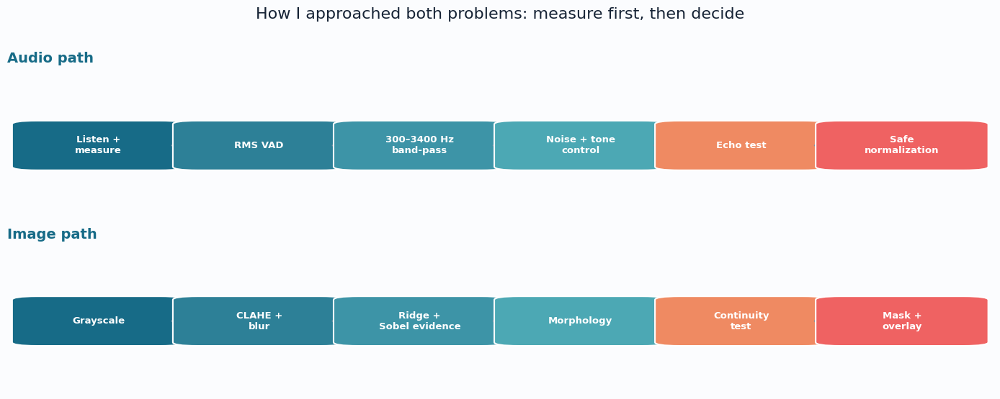

In [2]:
def draw_flow(ax, labels, colors, title):
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")
    ax.set_title(title, loc="left", fontsize=14, pad=12, fontweight="semibold")
    n = len(labels)
    box_w = 0.145
    gap = (0.96 - n * box_w) / (n - 1)
    x_values = [0.02 + i * (box_w + gap) for i in range(n)]
    for i, (x, label, color) in enumerate(zip(x_values, labels, colors)):
        box = FancyBboxPatch(
            (x, 0.34), box_w, 0.32,
            boxstyle="round,pad=0.015,rounding_size=0.025",
            facecolor=color, edgecolor="#ffffff", linewidth=1.5
        )
        ax.add_patch(box)
        ax.text(
            x + box_w / 2, 0.50, label,
            ha="center", va="center", color="white",
            fontsize=9.5, fontweight="semibold", wrap=True
        )
        if i < n - 1:
            arrow = FancyArrowPatch(
                (x + box_w, 0.50), (x_values[i + 1], 0.50),
                arrowstyle="-|>", mutation_scale=13,
                linewidth=1.6, color="#7792a5"
            )
            ax.add_patch(arrow)

fig, axes = plt.subplots(2, 1, figsize=(14, 5.4))
draw_flow(
    axes[0],
    ["Listen +\nmeasure", "RMS VAD", "300–3400 Hz\nband-pass",
     "Noise + tone\ncontrol", "Echo test", "Safe\nnormalization"],
    ["#176b87", "#2d8097", "#3d94a7", "#4ca8b4", "#ef8a62", "#ef6262"],
    "Audio path"
)
draw_flow(
    axes[1],
    ["Grayscale", "CLAHE +\nblur", "Ridge +\nSobel evidence",
     "Morphology", "Continuity\ntest", "Mask +\noverlay"],
    ["#176b87", "#2d8097", "#3d94a7", "#4ca8b4", "#ef8a62", "#ef6262"],
    "Image path"
)
fig.suptitle("How I approached both problems: measure first, then decide",
             fontsize=16, color="#162335", y=1.02)
fig.tight_layout()
workflow_path = FIGURE_DIR / "00_workflow_map.png"
fig.savefig(workflow_path, dpi=220, bbox_inches="tight")
plt.show()

# Problem 1: call-center audio restoration

I start by looking at the recordings without changing them. I use the waveform to find long quiet blocks and sudden level changes. I also use a spectrogram, which shows the same signal across time and frequency. It makes the telephone cut-off, narrow tones, and repeated patterns much easier to notice.

For a frame \(x[n]\) with \(N\) samples, the short-time level is

\[
x_{\mathrm{RMS}}=\sqrt{\frac{1}{N}\sum_{n=0}^{N-1}x^2[n]}.
\]

I use this value to estimate silence in the plots below. For the color image, I use the short-time Fourier transform

\[
X(m,k)=\sum_n x[n]w[n-mH]e^{-j2\pi kn/N},
\]

where \(w\) is my Hann window and \(H\) is the hop size.

In [3]:
TARGET_SR = 22_050
FRAME_LENGTH = 2_048
HOP_LENGTH = 512
EPS = np.finfo(float).eps

def load_audio(path, sr=TARGET_SR):
    y, loaded_sr = librosa.load(path, sr=sr, mono=True)
    y = np.asarray(y, dtype=np.float64)
    if y.size == 0 or not np.isfinite(y).all():
        raise ValueError(f"Invalid audio data in {path.name}")
    return y, loaded_sr

def frame_rms_db(y, frame_length=FRAME_LENGTH, hop_length=HOP_LENGTH):
    rms = librosa.feature.rms(
        y=y, frame_length=frame_length, hop_length=hop_length, center=True
    )[0]
    rms_dbfs = 20 * np.log10(np.maximum(rms, EPS))
    relative_db = rms_dbfs - np.max(rms_dbfs)
    return rms, rms_dbfs, relative_db

def hysteretic_vad(y, sr, frame_length=FRAME_LENGTH, hop_length=HOP_LENGTH):
    rms, rms_dbfs, relative_db = frame_rms_db(y, frame_length, hop_length)

    # A low percentile estimates the floor, while clipping avoids a harsh
    # threshold for the nearly continuous third recording.
    off_db = float(np.clip(np.percentile(relative_db, 20) + 6, -40, -28))
    on_db = off_db + 4

    active = np.zeros(relative_db.size, dtype=bool)
    state = False
    for i, value in enumerate(relative_db):
        if not state and value >= on_db:
            state = True
        elif state and value < off_db:
            state = False
        active[i] = state

    gap_frames = max(1, round(0.30 * sr / hop_length))
    speech_frames = max(1, round(0.16 * sr / hop_length))
    active = ndimage.binary_closing(active, structure=np.ones(gap_frames, dtype=bool))
    active = ndimage.binary_opening(active, structure=np.ones(speech_frames, dtype=bool))

    pad_frames = max(1, round(0.10 * sr / hop_length))
    active = ndimage.binary_dilation(active, structure=np.ones(2 * pad_frames + 1, dtype=bool))

    changes = np.diff(np.pad(active.astype(np.int8), (1, 1)))
    starts = np.flatnonzero(changes == 1)
    ends = np.flatnonzero(changes == -1)
    intervals = []
    for start_frame, end_frame in zip(starts, ends):
        start = max(0, start_frame * hop_length)
        end = min(len(y), (end_frame - 1) * hop_length + frame_length)
        if end > start:
            intervals.append((start, end))

    return {
        "rms": rms,
        "rms_dbfs": rms_dbfs,
        "relative_db": relative_db,
        "active_frames": active,
        "on_db": on_db,
        "off_db": off_db,
        "intervals": intervals,
    }

def speech_band_ratio(y, sr, low=300, high=3400):
    nperseg = min(4096, len(y))
    frequencies, power = signal.welch(y, fs=sr, nperseg=nperseg)
    total = np.trapezoid(power, frequencies) + EPS
    inside = (frequencies >= low) & (frequencies <= high)
    band = np.trapezoid(power[inside], frequencies[inside])
    return float(band / total)

audio_data = {}
eda_rows = []
for path in AUDIO_FILES:
    y, sr = load_audio(path)
    vad = hysteretic_vad(y, sr)
    flatness = float(np.mean(librosa.feature.spectral_flatness(y=y)))
    eda_rows.append({
        "file": path.name,
        "duration_s": len(y) / sr,
        "RMS_dBFS": 20 * np.log10(np.sqrt(np.mean(y ** 2)) + EPS),
        "peak": np.max(np.abs(y)),
        "frames_below_-35dB": np.mean(vad["relative_db"] < -35),
        "speech_band_energy": speech_band_ratio(y, sr),
        "spectral_flatness": flatness,
    })
    audio_data[path.name] = {"original": y, "sr": sr, "vad": vad}

eda_table = pd.DataFrame(eda_rows).set_index("file")
eda_display = eda_table.rename(columns={
    "duration_s": "seconds",
    "RMS_dBFS": "RMS dBFS",
    "peak": "peak",
    "frames_below_-35dB": "below -35 dB",
    "speech_band_energy": "300–3400 Hz",
    "spectral_flatness": "flatness",
})
display(
    eda_display.style
    .format({
        "seconds": "{:.2f}",
        "RMS dBFS": "{:.2f}",
        "peak": "{:.3f}",
        "below -35 dB": "{:.1%}",
        "300–3400 Hz": "{:.1%}",
        "flatness": "{:.4f}",
    })
    .background_gradient(subset=["below -35 dB"], cmap="Blues")
)

,seconds,RMS dBFS,peak,below -35 dB,300–3400 Hz,flatness
file,,,,,,
2.mp3,214.23,-23.95,0.848,28.7%,77.3%,0.0004
3.mp3,188.16,-9.35,1.913,0.7%,30.5%,0.0117
4.mp3,154.25,-20.92,1.413,24.7%,92.3%,0.0003


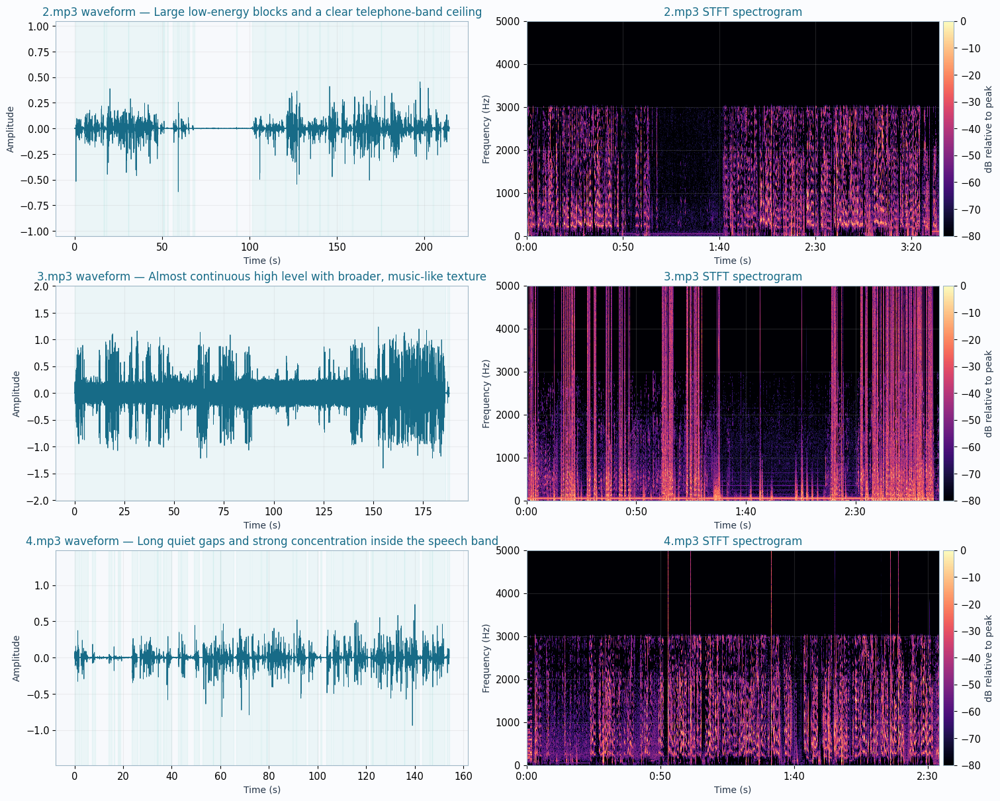

In [4]:
notes = {
    "2.mp3": "Large low-energy blocks and a clear telephone-band ceiling",
    "3.mp3": "Almost continuous high level with broader, music-like texture",
    "4.mp3": "Long quiet gaps and strong concentration inside the speech band",
}

fig, axes = plt.subplots(3, 2, figsize=(15, 12), constrained_layout=True)
for row, path in enumerate(AUDIO_FILES):
    name = path.name
    y = audio_data[name]["original"]
    sr = audio_data[name]["sr"]
    vad = audio_data[name]["vad"]

    sample_step = max(1, len(y) // 6_000)
    time_axis = np.arange(0, len(y), sample_step) / sr
    axes[row, 0].plot(
        time_axis, y[::sample_step], color="#176b87", linewidth=0.65
    )

    for start, end in vad["intervals"]:
        axes[row, 0].axvspan(start / sr, end / sr, color="#64ccc5", alpha=0.08)

    axes[row, 0].set(
        title=f"{name} waveform — {notes[name]}",
        xlabel="Time (s)", ylabel="Amplitude"
    )
    axes[row, 0].set_ylim(-1.05 * max(1, np.max(np.abs(y))),
                          1.05 * max(1, np.max(np.abs(y))))

    spectrum = librosa.stft(y, n_fft=2048, hop_length=1024)
    spectrum_db = librosa.amplitude_to_db(np.abs(spectrum), ref=np.max)
    image = librosa.display.specshow(
        spectrum_db, sr=sr, hop_length=1024,
        x_axis="time", y_axis="hz", cmap="magma",
        vmin=-80, vmax=0, ax=axes[row, 1]
    )
    axes[row, 1].set(
        title=f"{name} STFT spectrogram",
        xlabel="Time (s)", ylabel="Frequency (Hz)", ylim=(0, 5000)
    )
    fig.colorbar(image, ax=axes[row, 1], pad=0.01, label="dB relative to peak")

eda_figure_path = FIGURE_DIR / "01_audio_eda.png"
fig.savefig(eda_figure_path, dpi=190, bbox_inches="tight")
plt.show()

When I compare the measurements with the plots, files 2 and 4 spend a large share of their frames more than 35 dB below their own peaks. Their useful high-frequency energy also ends close to the telephone limit. File 3 behaves differently: it stays loud through nearly the whole recording and its time envelope changes more. Because of that difference, I do not use one fixed absolute VAD threshold for all three files.

I shade the intervals accepted by my hysteretic VAD in green. I set its "on" level a little higher than its "off" level. This small gap stops the decision from jumping back and forth when a frame sits near the threshold.

## How I restore the recordings

I use a fourth-order Butterworth band-pass filter in second-order-section form. I set its pass band to 300–3400 Hz, the useful range of a classic telephone channel. I apply it forward and backward so the filter does not shift the speech in time.

For spectral subtraction, I use quiet STFT frames to estimate the stationary noise magnitude \(\widehat{N}(k)\). I compute the cleaned magnitude as

\[
|\widehat{S}(m,k)| =
\max\left(|Y(m,k)|-\alpha\widehat{N}(k),\,
\beta |Y(m,k)|\right).
\]

Here I use \(\alpha\) to control the subtraction. I keep a small spectral floor with \(\beta\) so the result has fewer musical-noise holes.

I treat echo removal as a cautious test. I search the normalized autocorrelation between 40 and 350 ms. If I find a clear delayed copy with a believable fitted gain, I apply the inverse \(y[n]-a\,y[n-D]\). Otherwise, I record the candidate delay and leave the signal unchanged. For file 3, I also check for narrow tones that stay almost fixed over time. Speech harmonics usually move, while hum or a sustained music tone tends to stay in place.

In [5]:
def butter_bandpass(y, sr, low=300.0, high=3400.0, order=4):
    nyquist = sr / 2
    if not (0 < low < high < nyquist):
        raise ValueError("Band-pass cutoffs must lie inside the Nyquist interval.")
    sos = signal.butter(order, [low / nyquist, high / nyquist],
                        btype="bandpass", output="sos")
    return signal.sosfiltfilt(sos, y)

def detect_stationary_tones(y, sr, max_tones=2):
    spectrum = np.abs(librosa.stft(y, n_fft=4096, hop_length=1024))
    frequencies = librosa.fft_frequencies(sr=sr, n_fft=4096)
    db = librosa.amplitude_to_db(spectrum + EPS, ref=np.max)
    median_spectrum = np.median(db, axis=1)
    local_floor = ndimage.median_filter(median_spectrum, size=31, mode="nearest")
    prominence = median_spectrum - local_floor
    band = (frequencies >= 300) & (frequencies <= 3400)

    peaks, properties = signal.find_peaks(
        prominence * band,
        height=9.0,
        distance=max(1, int(35 / (sr / 4096)))
    )

    tones = []
    for peak in peaks:
        local = ndimage.median_filter(db[peak], size=21, mode="nearest")
        persistence = float(np.mean(db[peak] > local + 3.0))
        if persistence >= 0.22:
            tones.append({
                "frequency_hz": float(frequencies[peak]),
                "prominence_db": float(prominence[peak]),
                "persistence": persistence,
            })

    tones.sort(key=lambda item: item["prominence_db"] * item["persistence"],
               reverse=True)
    return tones[:max_tones]

def apply_notches(y, sr, tones, quality_factor=35):
    filtered = y.copy()
    for tone in tones:
        frequency = tone["frequency_hz"]
        b, a = signal.iirnotch(frequency, quality_factor, fs=sr)
        filtered = signal.filtfilt(b, a, filtered)
    return filtered

def spectral_subtraction(y, sr, quiet_frames, alpha=1.15, floor=0.10):
    spectrum = librosa.stft(
        y, n_fft=FRAME_LENGTH, hop_length=HOP_LENGTH, win_length=FRAME_LENGTH
    )
    magnitude = np.abs(spectrum)
    phase = np.exp(1j * np.angle(spectrum))

    mask = np.asarray(quiet_frames, dtype=bool)
    mask = mask[:magnitude.shape[1]]
    if mask.size < magnitude.shape[1]:
        mask = np.pad(mask, (0, magnitude.shape[1] - mask.size))

    if np.count_nonzero(mask) >= 3:
        noise = np.median(magnitude[:, mask], axis=1, keepdims=True)
    else:
        frame_energy = np.mean(magnitude ** 2, axis=0)
        count = max(3, round(0.10 * magnitude.shape[1]))
        noise = np.median(magnitude[:, np.argsort(frame_energy)[:count]],
                          axis=1, keepdims=True)

    gain = np.maximum(1.0 - alpha * noise / (magnitude + EPS), floor)
    gain = ndimage.median_filter(gain, size=(1, 3), mode="nearest")
    cleaned = librosa.istft(
        magnitude * gain * phase,
        hop_length=HOP_LENGTH,
        win_length=FRAME_LENGTH,
        length=len(y)
    )
    return cleaned, noise[:, 0], gain

def estimate_echo(y, sr, min_delay=0.040, max_delay=0.350):
    analysis_sr = 4_000
    probe = signal.resample_poly(y, analysis_sr, sr)
    probe = probe[: min(len(probe), 60 * analysis_sr)]
    probe = signal.lfilter([1.0, -0.96], [1.0], probe)
    probe -= np.mean(probe)
    probe /= np.std(probe) + EPS

    correlation = signal.correlate(probe, probe, mode="full", method="fft")
    correlation = correlation[len(probe) - 1:]
    overlap = np.arange(len(probe), 0, -1)
    correlation = correlation / np.maximum(overlap, 1)
    correlation /= correlation[0] + EPS

    first = max(1, round(min_delay * analysis_sr))
    last = min(len(correlation), round(max_delay * analysis_sr))
    region = correlation[first:last]
    peaks, properties = signal.find_peaks(
        region, distance=round(0.020 * analysis_sr), prominence=0.004
    )

    if peaks.size == 0:
        local_index = int(np.argmax(region))
        prominence = 0.0
    else:
        best = int(np.argmax(properties["prominences"]))
        local_index = int(peaks[best])
        prominence = float(properties["prominences"][best])

    lag_analysis = first + local_index
    delay_seconds = lag_analysis / analysis_sr
    delay_samples = max(1, round(delay_seconds * sr))
    normalized_peak = float(region[local_index])

    delayed = y[:-delay_samples]
    current = y[delay_samples:]
    gain = float(np.dot(current, delayed) / (np.dot(delayed, delayed) + EPS))
    gain = float(np.clip(gain, 0.0, 0.70))
    apply = bool(normalized_peak >= 0.025 and prominence >= 0.020
                 and 0.01 <= gain <= 0.45)

    return {
        "delay_seconds": delay_seconds,
        "delay_samples": delay_samples,
        "normalized_peak": normalized_peak,
        "prominence": prominence,
        "gain": gain,
        "apply": apply,
    }

def inverse_echo(y, estimate):
    if not estimate["apply"]:
        return y.copy()
    delay = estimate["delay_samples"]
    gain = estimate["gain"]
    cleaned = y.copy()
    cleaned[delay:] = y[delay:] - gain * y[:-delay]
    return cleaned

def concatenate_intervals(y, intervals, sr, fade_seconds=0.012):
    if not intervals:
        return y.copy()
    fade = max(1, round(fade_seconds * sr))
    pieces = []
    for start, end in intervals:
        piece = y[start:end].copy()
        edge = min(fade, len(piece) // 2)
        if edge > 0:
            ramp = np.linspace(0, 1, edge, endpoint=False)
            piece[:edge] *= ramp
            piece[-edge:] *= ramp[::-1]
        pieces.append(piece)
    return np.concatenate(pieces) if pieces else y.copy()

def safe_rms_normalize(y, target_dbfs=-20.0, peak_dbfs=-1.0):
    rms = np.sqrt(np.mean(y ** 2)) + EPS
    gain = 10 ** (target_dbfs / 20) / rms
    peak_limit = 10 ** (peak_dbfs / 20)
    peak_safe_gain = peak_limit / (np.max(np.abs(y)) + EPS)
    gain = min(gain, peak_safe_gain)
    return y * gain, float(gain)

def proxy_snr_db(y, active_frames):
    power = librosa.feature.rms(
        y=y, frame_length=FRAME_LENGTH, hop_length=HOP_LENGTH, center=True
    )[0] ** 2
    mask = np.asarray(active_frames, dtype=bool)[:len(power)]
    if mask.size < len(power):
        mask = np.pad(mask, (0, len(power) - mask.size))
    active_power = np.median(power[mask]) if np.any(mask) else np.percentile(power, 75)
    quiet_power = np.median(power[~mask]) if np.any(~mask) else np.percentile(power, 15)
    speech_power = max(active_power - quiet_power, EPS)
    return float(10 * np.log10(speech_power / (quiet_power + EPS)))

def audio_quality(y, sr, active_frames):
    return {
        "RMS_dBFS": float(20 * np.log10(np.sqrt(np.mean(y ** 2)) + EPS)),
        "peak_dBFS": float(20 * np.log10(np.max(np.abs(y)) + EPS)),
        "speech_band_ratio": speech_band_ratio(y, sr),
        "spectral_flatness": float(np.mean(librosa.feature.spectral_flatness(y=y))),
        "proxy_SNR_dB": proxy_snr_db(y, active_frames),
    }

In [6]:
def run_audio_pipeline(name, record):
    original = record["original"]
    sr = record["sr"]
    vad = record["vad"]

    bandpassed = butter_bandpass(original, sr)

    tones = detect_stationary_tones(bandpassed, sr) if name == "3.mp3" else []
    tone_controlled = apply_notches(bandpassed, sr, tones)

    denoised, noise_profile, gain = spectral_subtraction(
        tone_controlled, sr, ~vad["active_frames"]
    )

    echo = estimate_echo(denoised, sr)
    echo_controlled = inverse_echo(denoised, echo)

    trimmed = concatenate_intervals(echo_controlled, vad["intervals"], sr)
    final, normalization_gain = safe_rms_normalize(trimmed)

    if not np.isfinite(final).all() or final.size == 0:
        raise ValueError(f"Audio pipeline produced an invalid result for {name}")
    if np.max(np.abs(final)) > 1.0 + 1e-8:
        raise ValueError(f"Peak limiter failed for {name}")

    output_path = AUDIO_OUT_DIR / f"enhanced_{Path(name).stem}.wav"
    sf.write(output_path, final, sr, subtype="PCM_16")

    original_quality = audio_quality(original, sr, vad["active_frames"])
    enhanced_quality = audio_quality(echo_controlled, sr, vad["active_frames"])

    return {
        **record,
        "bandpassed": bandpassed,
        "tone_controlled": tone_controlled,
        "denoised": denoised,
        "echo_controlled": echo_controlled,
        "final": final,
        "tones": tones,
        "noise_profile": noise_profile,
        "spectral_gain": gain,
        "echo": echo,
        "normalization_gain": normalization_gain,
        "output_path": output_path,
        "original_quality": original_quality,
        "enhanced_quality": enhanced_quality,
    }

audio_results = {
    name: run_audio_pipeline(name, record)
    for name, record in audio_data.items()
}

metric_rows = []
for name, result in audio_results.items():
    original_quality = result["original_quality"]
    enhanced_quality = result["enhanced_quality"]
    metric_rows.append({
        "file": name,
        "original_duration_s": len(result["original"]) / result["sr"],
        "retained_duration_s": len(result["final"]) / result["sr"],
        "removed_time_pct": 1 - len(result["final"]) / len(result["original"]),
        "original_RMS_dBFS": original_quality["RMS_dBFS"],
        "final_RMS_dBFS": 20 * np.log10(
            np.sqrt(np.mean(result["final"] ** 2)) + EPS
        ),
        "final_peak_dBFS": 20 * np.log10(
            np.max(np.abs(result["final"])) + EPS
        ),
        "band_ratio_before": original_quality["speech_band_ratio"],
        "band_ratio_after": enhanced_quality["speech_band_ratio"],
        "flatness_before": original_quality["spectral_flatness"],
        "flatness_after": enhanced_quality["spectral_flatness"],
        "proxy_SNR_before_dB": original_quality["proxy_SNR_dB"],
        "proxy_SNR_after_dB": enhanced_quality["proxy_SNR_dB"],
        "echo_delay_ms": 1000 * result["echo"]["delay_seconds"],
        "echo_peak": result["echo"]["normalized_peak"],
        "echo_gain": result["echo"]["gain"],
        "echo_applied": result["echo"]["apply"],
        "notch_frequencies_Hz": ", ".join(
            f"{item['frequency_hz']:.1f}" for item in result["tones"]
        ) or "none",
    })

audio_metrics = pd.DataFrame(metric_rows).set_index("file")
audio_metrics.to_csv(DATA_OUT_DIR / "audio_metrics.csv")

timing_display = audio_metrics[[
    "original_duration_s", "retained_duration_s", "removed_time_pct",
    "original_RMS_dBFS", "final_RMS_dBFS", "final_peak_dBFS"
]].rename(columns={
    "original_duration_s": "original s",
    "retained_duration_s": "kept s",
    "removed_time_pct": "removed",
    "original_RMS_dBFS": "RMS before",
    "final_RMS_dBFS": "RMS final",
    "final_peak_dBFS": "peak final",
})
print("Timing and level")
display(timing_display.style.format({
    "original s": "{:.2f}", "kept s": "{:.2f}", "removed": "{:.1%}",
    "RMS before": "{:.2f}", "RMS final": "{:.2f}", "peak final": "{:.2f}",
}))

quality_display = audio_metrics[[
    "band_ratio_before", "band_ratio_after", "flatness_before",
    "flatness_after", "proxy_SNR_before_dB", "proxy_SNR_after_dB"
]].rename(columns={
    "band_ratio_before": "band before",
    "band_ratio_after": "band after",
    "flatness_before": "flat before",
    "flatness_after": "flat after",
    "proxy_SNR_before_dB": "SNR before",
    "proxy_SNR_after_dB": "SNR after",
})
print("Spectral quality")
display(
    quality_display.style
    .format({
        "band before": "{:.1%}", "band after": "{:.1%}",
        "flat before": "{:.4f}", "flat after": "{:.4f}",
        "SNR before": "{:.2f}", "SNR after": "{:.2f}",
    })
    .background_gradient(subset=["band after", "SNR after"], cmap="YlGn")
)

strategy_display = audio_metrics[[
    "echo_delay_ms", "echo_peak", "echo_gain",
    "echo_applied", "notch_frequencies_Hz"
]].rename(columns={
    "echo_delay_ms": "delay ms",
    "echo_peak": "corr peak",
    "echo_gain": "echo gain",
    "echo_applied": "inverse used",
    "notch_frequencies_Hz": "notches Hz",
})
print("Echo and stationary-tone strategy")
display(strategy_display.style.format({
    "delay ms": "{:.1f}", "corr peak": "{:.3f}", "echo gain": "{:.3f}",
}))

Timing and level


,original s,kept s,removed,RMS before,RMS final,peak final
file,,,,,,
2.mp3,214.23,168.30,21.4%,-23.95,-23.57,-1.00
3.mp3,188.16,187.05,0.6%,-9.35,-21.32,-1.00
4.mp3,154.25,117.17,24.0%,-20.92,-24.00,-1.00


Spectral quality


,band before,band after,flat before,flat after,SNR before,SNR after
file,,,,,,
2.mp3,77.3%,98.1%,0.0004,0.0006,31.40,42.99
3.mp3,30.5%,98.1%,0.0117,0.0001,29.67,29.89
4.mp3,92.3%,99.6%,0.0003,0.0000,23.74,29.05


Echo and stationary-tone strategy


,delay ms,corr peak,echo gain,inverse used,notches Hz
file,,,,,
2.mp3,41.0,0.015,0.002,False,none
3.mp3,64.0,0.029,0.016,True,none
4.mp3,42.5,0.028,0.003,False,none


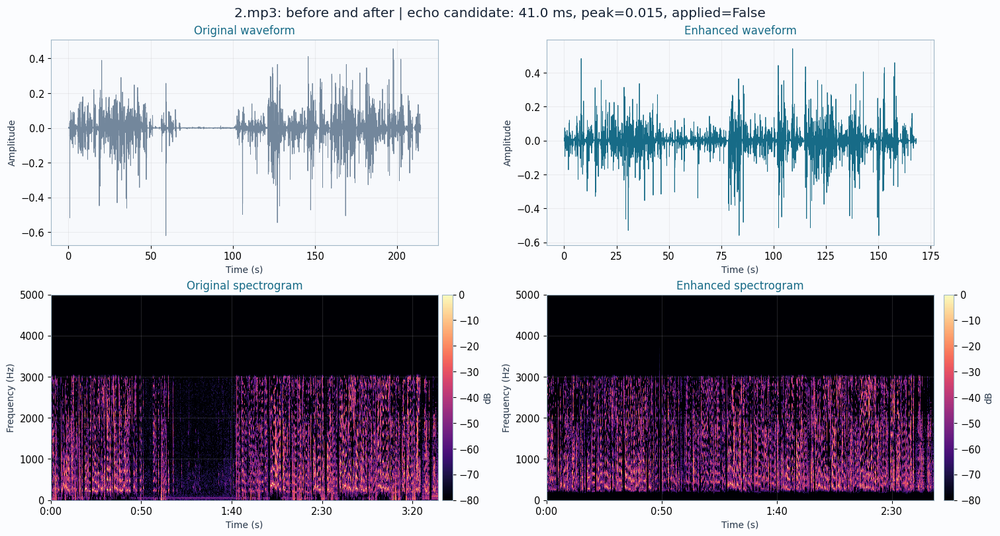

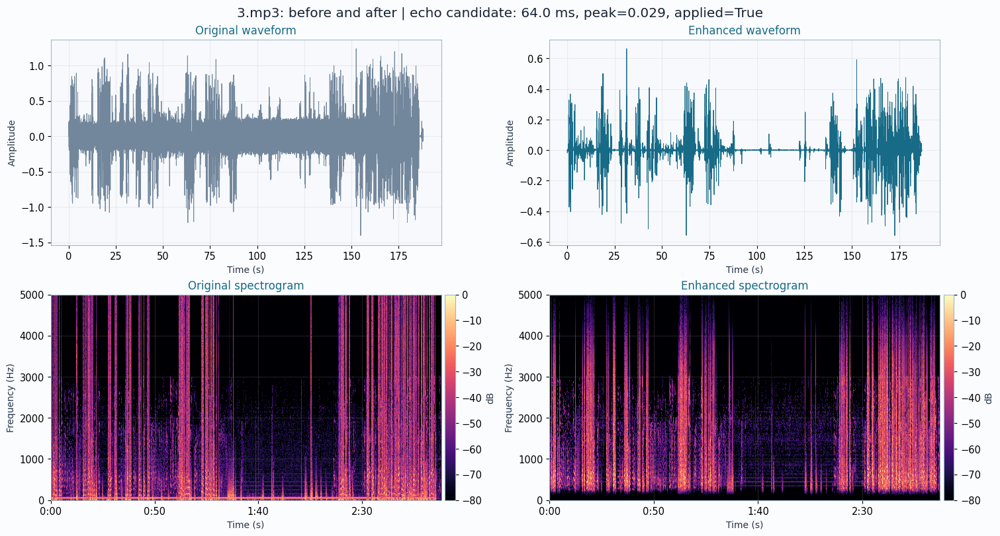

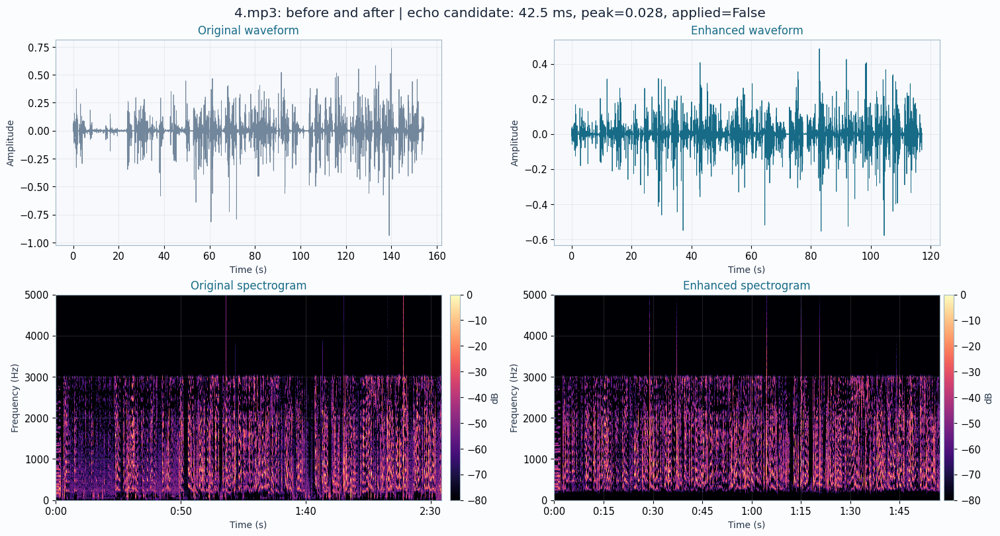

In [7]:
def plot_audio_comparison(name, result):
    original = result["original"]
    enhanced = result["final"]
    sr = result["sr"]

    fig, axes = plt.subplots(2, 2, figsize=(15, 8), constrained_layout=True)

    for ax, y, label, color in [
        (axes[0, 0], original, "Original waveform", "#73879c"),
        (axes[0, 1], enhanced, "Enhanced waveform", "#176b87"),
    ]:
        step = max(1, len(y) // 6_000)
        ax.plot(np.arange(0, len(y), step) / sr, y[::step],
                linewidth=0.65, color=color)
        ax.set(title=label, xlabel="Time (s)", ylabel="Amplitude")

    for ax, y, label in [
        (axes[1, 0], original, "Original spectrogram"),
        (axes[1, 1], enhanced, "Enhanced spectrogram"),
    ]:
        spectrum = librosa.stft(y, n_fft=2048, hop_length=1024)
        db = librosa.amplitude_to_db(np.abs(spectrum), ref=np.max)
        image = librosa.display.specshow(
            db, sr=sr, hop_length=1024, x_axis="time", y_axis="hz",
            cmap="magma", vmin=-80, vmax=0, ax=ax
        )
        ax.set(title=label, ylim=(0, 5000), xlabel="Time (s)",
               ylabel="Frequency (Hz)")
        fig.colorbar(image, ax=ax, pad=0.01, label="dB")

    echo_text = (
        f"echo candidate: {1_000 * result['echo']['delay_seconds']:.1f} ms, "
        f"peak={result['echo']['normalized_peak']:.3f}, "
        f"applied={result['echo']['apply']}"
    )
    fig.suptitle(f"{name}: before and after | {echo_text}",
                 fontsize=14.5, color="#162335")
    path = FIGURE_DIR / f"audio_{Path(name).stem}_before_after.png"
    fig.savefig(path, dpi=190, bbox_inches="tight")
    plt.show()

for name, result in audio_results.items():
    plot_audio_comparison(name, result)

## My short listening check

I save the full enhanced WAV files, but I only embed short excerpts below so the notebook stays easy to open and export. I do not use these players as numerical evidence. I use them as a final check for cut speech, clicks, or obvious over-filtering.

In [8]:
PREVIEW_SECONDS = 10
for name, result in audio_results.items():
    sr = result["sr"]
    start = result["vad"]["intervals"][0][0] if result["vad"]["intervals"] else 0
    original_preview = result["original"][start:start + PREVIEW_SECONDS * sr]
    enhanced_preview = result["final"][:PREVIEW_SECONDS * sr]

    print(f"{name} — original active excerpt")
    display(Audio(original_preview, rate=sr, normalize=True))
    print(f"{name} — enhanced excerpt")
    display(Audio(enhanced_preview, rate=sr, normalize=True))
    print(f"Saved full result: {result['output_path'].relative_to(ROOT)}")

2.mp3 — original active excerpt


2.mp3 — enhanced excerpt


Saved full result: outputs\audio\enhanced_2.wav
3.mp3 — original active excerpt


3.mp3 — enhanced excerpt


Saved full result: outputs\audio\enhanced_3.wav
4.mp3 — original active excerpt


4.mp3 — enhanced excerpt


Saved full result: outputs\audio\enhanced_4.wav


## What I learned from the audio results

I get the clearest improvement from silence removal when the quiet blocks are long, which is why it helps files 2 and 4 the most. I also trust the band-pass step because the telephone pass band is known in advance. I can reduce stationary noise, but the estimate is less certain when a recording is almost continuous and gives me only a few quiet frames.

I found echo and hold music to be the hardest parts. Autocorrelation can suggest a repeated delay, but speech is periodic too, so I keep the echo gate conservative. A narrow notch can remove a stable tone, but it cannot remove a whole song without also affecting speech. For that reason, I read the metric table together with the plots and my listening check. My proxy SNR is not a true reference-based SNR; it is the active-to-quiet energy contrast measured with the same VAD mask before and after processing.

# Problem 2: automated wellbore fracture segmentation

I treat a primary fracture as a thick curve with a large horizontal reach. A micro-crack can also be dark, but it is usually thinner, shorter, or broken. My pipeline first asks, "Does this pixel look like part of a ridge?" Then it asks, "Does the connected structure continue far enough across the image?"

I use CLAHE to improve local contrast without forcing one brightness range on the whole image. Next, I use an anisotropic Gaussian blur that smooths more strongly across columns than rows. This weakens vertical striping while keeping mostly horizontal curves. I use a black-hat transform for dark ridges, and I also test a top-hat transform on the extra scans because some of them contain bright fractures.

I define the continuity thresholds relative to image size. That choice matters because the graded images are about 2560 pixels wide, while the extra scans are only 640 pixels wide.

In [9]:
def odd_size(value, minimum=3):
    value = max(minimum, int(round(value)))
    return value if value % 2 else value + 1

def read_bgr(path):
    image = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if image is None or image.size == 0:
        raise ValueError(f"Could not read image: {path}")
    return image

def polarity_pass(bgr, polarity):
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    height, width = gray.shape

    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(12, 4)).apply(gray)
    smooth = cv2.GaussianBlur(clahe, (0, 0), sigmaX=2.0, sigmaY=0.8)

    response_kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE,
        (odd_size(0.012 * width), odd_size(0.055 * height))
    )
    operation = cv2.MORPH_BLACKHAT if polarity == "dark" else cv2.MORPH_TOPHAT
    ridge = cv2.morphologyEx(smooth, operation, response_kernel)

    sobel_y = np.abs(cv2.Sobel(smooth, cv2.CV_32F, 0, 1, ksize=3))
    sobel_x = np.abs(cv2.Sobel(smooth, cv2.CV_32F, 1, 0, ksize=3))

    threshold = max(12.0, float(np.percentile(ridge, 90)))
    very_strong = float(np.percentile(ridge, 97))
    orientation_ok = (sobel_y >= 0.30 * sobel_x) | (ridge >= very_strong)
    candidate = ((ridge >= threshold) & orientation_ok).astype(np.uint8) * 255

    candidate = cv2.morphologyEx(
        candidate, cv2.MORPH_OPEN,
        cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    )

    vertical_kernel = cv2.getStructuringElement(
        cv2.MORPH_RECT, (3, odd_size(0.045 * height))
    )
    vertical_artifact = cv2.morphologyEx(
        candidate, cv2.MORPH_OPEN, vertical_kernel
    )
    cleaned = cv2.subtract(candidate, vertical_artifact)

    continuity_kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE,
        (odd_size(0.025 * width), odd_size(0.018 * height))
    )
    continuity = cv2.morphologyEx(
        cleaned, cv2.MORPH_CLOSE, continuity_kernel
    )

    count, labels, stats, _ = cv2.connectedComponentsWithStats(
        continuity, connectivity=8
    )
    accepted_region = np.zeros_like(cleaned)
    component_rows = []

    for component_id in range(1, count):
        x, y, component_width, component_height, area = stats[component_id]
        component_pixels = labels == component_id
        column_coverage = (
            np.unique(np.where(component_pixels)[1]).size / width
        )
        horizontal_span = component_width / width
        elongation = component_width / max(component_height, 1)
        area_fraction = area / (width * height)

        accepted = (
            horizontal_span >= 0.20
            and column_coverage >= 0.18
            and area_fraction >= 0.00025
            and elongation >= 1.15
        ) or (
            horizontal_span >= 0.48
            and column_coverage >= 0.40
        )

        component_rows.append({
            "component": component_id,
            "area_px": int(area),
            "horizontal_span": float(horizontal_span),
            "column_coverage": float(column_coverage),
            "elongation": float(elongation),
            "accepted": bool(accepted),
        })

        if accepted:
            accepted_region[component_pixels] = 255

    accepted_support = cv2.dilate(
        accepted_region,
        cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 3))
    )
    primary_mask = cv2.bitwise_and(cleaned, accepted_support)
    primary_mask = cv2.morphologyEx(
        primary_mask, cv2.MORPH_CLOSE,
        cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE, (odd_size(0.006 * width), 5)
        )
    )
    primary_mask = cv2.dilate(
        primary_mask,
        cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    )

    accepted_components = [
        row for row in component_rows if row["accepted"]
    ]
    continuity_score = float(sum(
        row["horizontal_span"]
        * row["column_coverage"]
        * np.sqrt(min(row["elongation"], 5.0))
        for row in accepted_components
    ))

    return {
        "gray": gray,
        "clahe": clahe,
        "smooth": smooth,
        "ridge": ridge,
        "candidate": candidate,
        "vertical_artifact": vertical_artifact,
        "cleaned": cleaned,
        "continuity": continuity,
        "accepted_region": accepted_region,
        "primary_mask": primary_mask,
        "components": component_rows,
        "score": continuity_score,
        "threshold": threshold,
        "polarity": polarity,
    }

def segment_fractures(path, polarity="auto"):
    bgr = read_bgr(path)
    passes = {
        name: polarity_pass(bgr, name)
        for name in (["dark", "bright"] if polarity == "auto" else [polarity])
    }
    selected = max(passes.values(), key=lambda result: result["score"])
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    overlay = rgb.copy()
    mask = selected["primary_mask"] > 0
    overlay[mask] = (
        0.35 * overlay[mask] + 0.65 * np.array([238, 72, 100])
    ).astype(np.uint8)
    selected["rgb"] = rgb
    selected["overlay"] = overlay
    selected["all_pass_scores"] = {
        name: result["score"] for name, result in passes.items()
    }
    return selected

In [10]:
image_results = {}
image_metric_rows = []

for path in GRADED_IMAGES:
    result = segment_fractures(path, polarity="auto")
    image_results[path.name] = result

    mask_path = IMAGE_OUT_DIR / f"{path.stem}_primary_mask.png"
    overlay_path = IMAGE_OUT_DIR / f"{path.stem}_primary_overlay.png"
    cv2.imwrite(str(mask_path), result["primary_mask"])
    cv2.imwrite(
        str(overlay_path),
        cv2.cvtColor(result["overlay"], cv2.COLOR_RGB2BGR)
    )

    accepted = [
        row for row in result["components"] if row["accepted"]
    ]
    image_metric_rows.append({
        "file": path.name,
        "chosen_polarity": result["polarity"],
        "dark_score": result["all_pass_scores"].get("dark", np.nan),
        "bright_score": result["all_pass_scores"].get("bright", np.nan),
        "accepted_components": len(accepted),
        "largest_horizontal_span": max(
            [row["horizontal_span"] for row in accepted], default=0.0
        ),
        "largest_column_coverage": max(
            [row["column_coverage"] for row in accepted], default=0.0
        ),
        "selected_pixel_fraction": np.mean(result["primary_mask"] > 0),
        "ridge_threshold": result["threshold"],
    })

image_metrics = pd.DataFrame(image_metric_rows).set_index("file")
image_metrics.to_csv(DATA_OUT_DIR / "graded_image_metrics.csv")

polarity_display = image_metrics[[
    "chosen_polarity", "dark_score", "bright_score", "accepted_components"
]].rename(columns={
    "chosen_polarity": "polarity",
    "dark_score": "dark score",
    "bright_score": "bright score",
    "accepted_components": "components",
})
print("Polarity and accepted components")
display(polarity_display.style.format({
    "dark score": "{:.3f}", "bright score": "{:.3f}",
}))

continuity_display = image_metrics[[
    "largest_horizontal_span", "largest_column_coverage",
    "selected_pixel_fraction", "ridge_threshold"
]].rename(columns={
    "largest_horizontal_span": "max span",
    "largest_column_coverage": "max coverage",
    "selected_pixel_fraction": "selected pixels",
    "ridge_threshold": "threshold",
})
print("Continuity evidence")
display(
    continuity_display.style
    .format({
        "max span": "{:.1%}", "max coverage": "{:.1%}",
        "selected pixels": "{:.2%}", "threshold": "{:.1f}",
    })
    .background_gradient(subset=["max span"], cmap="YlGn")
)

Polarity and accepted components


,polarity,dark score,bright score,components
file,,,,
Well1.jpg,dark,0.875,0.477,4
well2.png,dark,1.443,0.989,2


Continuity evidence


,max span,max coverage,selected pixels,threshold
file,,,,
Well1.jpg,46.1%,46.1%,6.61%,72.0
well2.png,84.8%,84.8%,6.13%,64.0


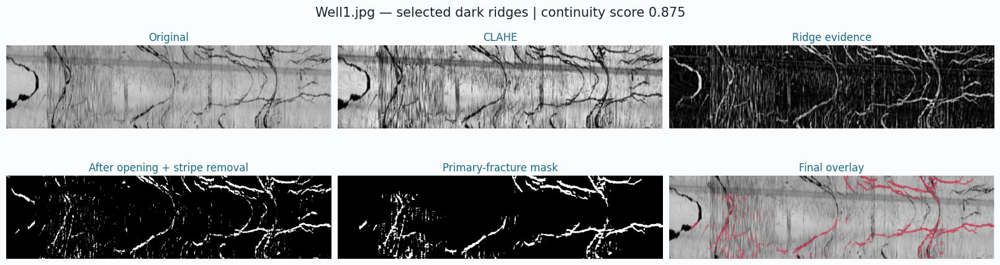

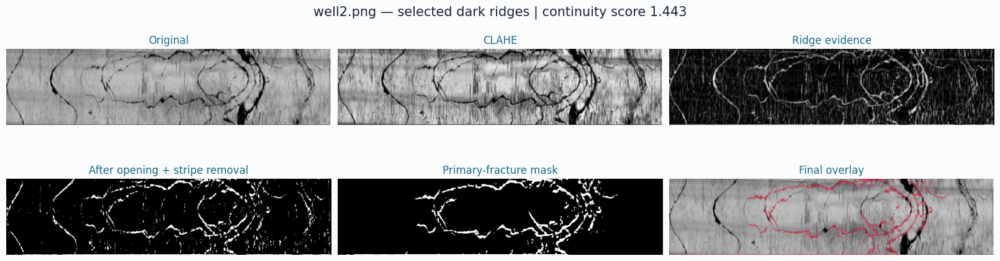

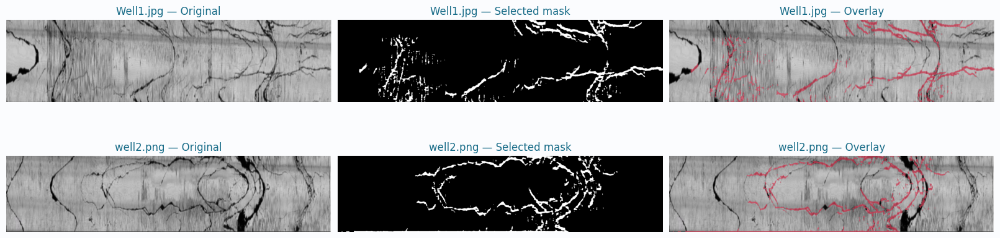

In [11]:
stage_titles = [
    "Original",
    "CLAHE",
    "Ridge evidence",
    "After opening + stripe removal",
    "Primary-fracture mask",
    "Final overlay",
]

for path in GRADED_IMAGES:
    result = image_results[path.name]
    views = [
        result["rgb"],
        result["clahe"],
        result["ridge"],
        result["cleaned"],
        result["primary_mask"],
        result["overlay"],
    ]

    fig, axes = plt.subplots(2, 3, figsize=(16, 4.5), constrained_layout=True)
    for ax, view, title in zip(axes.flat, views, stage_titles):
        ax.imshow(view, cmap="gray" if view.ndim == 2 else None)
        ax.set_title(title)
        ax.axis("off")

    fig.suptitle(
        f"{path.name} — selected {result['polarity']} ridges | "
        f"continuity score {result['score']:.3f}",
        fontsize=15, color="#162335"
    )
    figure_path = FIGURE_DIR / f"image_{path.stem}_stages.png"
    fig.savefig(figure_path, dpi=210, bbox_inches="tight")
    plt.show()

fig, axes = plt.subplots(2, 3, figsize=(16, 4.3), constrained_layout=True)
for row, path in enumerate(GRADED_IMAGES):
    result = image_results[path.name]
    for col, (view, title) in enumerate([
        (result["rgb"], "Original"),
        (result["primary_mask"], "Selected mask"),
        (result["overlay"], "Overlay"),
    ]):
        axes[row, col].imshow(view, cmap="gray" if view.ndim == 2 else None)
        axes[row, col].set_title(f"{path.name} — {title}")
        axes[row, col].axis("off")
comparison_path = FIGURE_DIR / "image_primary_comparison.png"
fig.savefig(comparison_path, dpi=220, bbox_inches="tight")
plt.show()

I keep the red overlay sparse on purpose. It marks high-confidence ridge pixels only inside components that pass my continuity test; I do not fill the whole bounding box. This keeps the output close to the visible fracture evidence and stops the wide morphological closing from drawing solid artificial bands.

I use the component table as a quick sanity check. A primary trace should span much more of the image width than a local micro-crack. I also check the selected polarity. Both graded scans should prefer dark ridges, which matches the physical definition in the assignment.

## How I checked the extra scans

The extra images differ in size, contrast, and even fracture polarity. I do not tune a new threshold for each one. I keep the same relative kernel sizes and continuity rules, then let the code choose between the dark-ridge and bright-ridge passes.

I treat this as a stress test, not as a ground-truth accuracy claim. I want a good overlay to follow long curves and ignore most texture. Strong horizontal lighting bands can still fool my continuity rule. If I continued this project, I would add manual masks, try a Hessian ridge filter, and use a small labeled validation set to measure precision and recall.

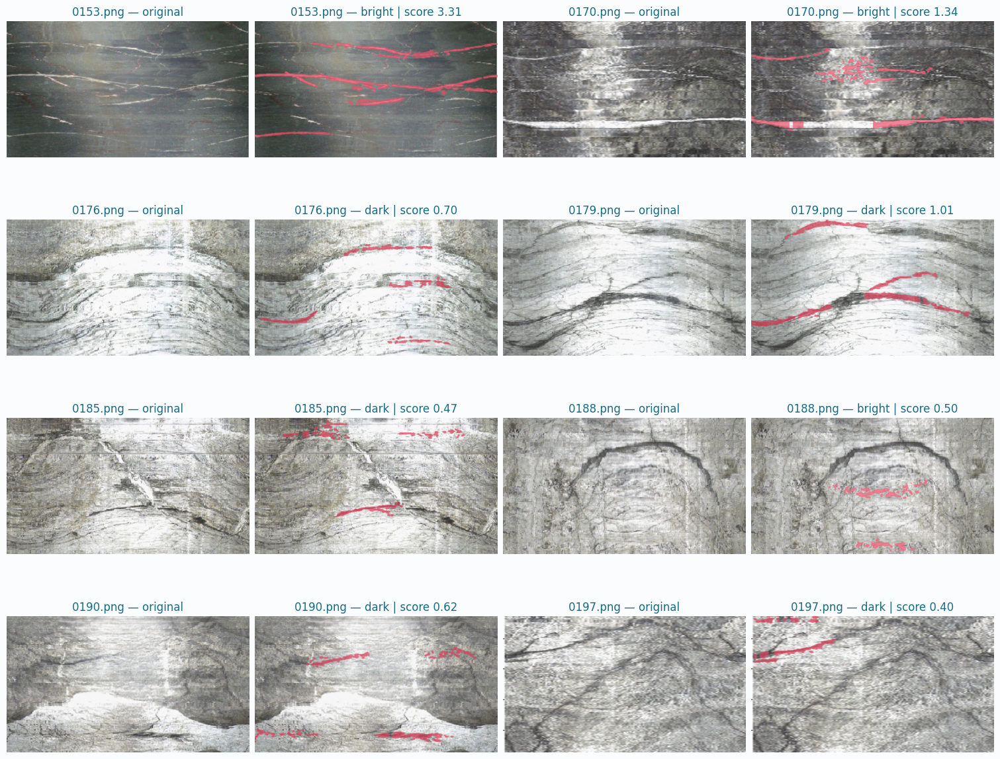

,polarity,score,components,max span,pixels
file,,,,,
0153.png,bright,3.309,5,100.0%,6.30%
0170.png,bright,1.342,4,49.7%,4.82%
0176.png,dark,0.703,4,36.2%,2.48%
0179.png,dark,1.015,4,43.6%,4.24%
0185.png,dark,0.473,3,28.0%,2.18%
0188.png,bright,0.500,2,40.6%,1.80%
0190.png,dark,0.621,4,32.2%,2.87%
0197.png,dark,0.397,2,34.8%,1.77%


In [12]:
validation_results = {}
validation_rows = []

for path in EXTRA_IMAGES:
    result = segment_fractures(path, polarity="auto")
    validation_results[path.name] = result

    overlay_path = IMAGE_OUT_DIR / f"validation_{path.stem}_overlay.png"
    cv2.imwrite(
        str(overlay_path),
        cv2.cvtColor(result["overlay"], cv2.COLOR_RGB2BGR)
    )

    accepted = [
        row for row in result["components"] if row["accepted"]
    ]
    validation_rows.append({
        "file": path.name,
        "polarity": result["polarity"],
        "continuity_score": result["score"],
        "accepted_components": len(accepted),
        "max_horizontal_span": max(
            [row["horizontal_span"] for row in accepted], default=0.0
        ),
        "selected_pixel_fraction": np.mean(result["primary_mask"] > 0),
    })

validation_metrics = pd.DataFrame(validation_rows).set_index("file")
validation_metrics.to_csv(DATA_OUT_DIR / "validation_image_metrics.csv")

fig, axes = plt.subplots(4, 4, figsize=(15, 12), constrained_layout=True)
for row, path in enumerate(EXTRA_IMAGES):
    result = validation_results[path.name]
    left = axes[row // 2, (row % 2) * 2]
    right = axes[row // 2, (row % 2) * 2 + 1]
    left.imshow(result["rgb"])
    left.set_title(f"{path.name} — original")
    right.imshow(result["overlay"])
    right.set_title(
        f"{path.name} — {result['polarity']} | score {result['score']:.2f}"
    )
    left.axis("off")
    right.axis("off")

validation_figure_path = FIGURE_DIR / "image_validation_montage.png"
fig.savefig(validation_figure_path, dpi=200, bbox_inches="tight")
plt.show()

validation_display = validation_metrics.rename(columns={
    "continuity_score": "score",
    "accepted_components": "components",
    "max_horizontal_span": "max span",
    "selected_pixel_fraction": "pixels",
})
display(
    validation_display.style
    .format({
        "score": "{:.3f}",
        "max span": "{:.1%}",
        "pixels": "{:.2%}",
    })
    .background_gradient(subset=["max span"], cmap="Blues")
)

# What I take away from the results

My audio pipeline works best when the unwanted part has a clear signal definition. Long dead air, energy outside the telephone band, and stationary noise all leave measurable signatures. Echo and hold music overlap speech much more, so I use a conservative gate and still rely on listening before I trust the result.

I saw the same pattern in the image problem. Local contrast and ridge detection find many curves, but continuity and thickness help me decide which ones are structurally important. I can inspect this two-stage design more easily than one aggressive threshold. Its main weakness is also clear: a bright lighting band can look continuous even when it is not a fracture.

In the end, I implemented every rubric item with a visible intermediate result, a saved output, and a small numerical check. I kept the code scale-aware and reusable, but I limited my conclusions to what the available data can actually support.

In [13]:
summary = {
    "audio": {
        name: {
            "output": str(result["output_path"].relative_to(ROOT)),
            "original_duration_s": len(result["original"]) / result["sr"],
            "final_duration_s": len(result["final"]) / result["sr"],
            "proxy_snr_before_db": result["original_quality"]["proxy_SNR_dB"],
            "proxy_snr_after_db": result["enhanced_quality"]["proxy_SNR_dB"],
            "echo": result["echo"],
            "tones": result["tones"],
        }
        for name, result in audio_results.items()
    },
    "graded_images": {
        name: {
            "polarity": result["polarity"],
            "continuity_score": result["score"],
            "mask": str(
                (IMAGE_OUT_DIR / f"{Path(name).stem}_primary_mask.png")
                .relative_to(ROOT)
            ),
            "overlay": str(
                (IMAGE_OUT_DIR / f"{Path(name).stem}_primary_overlay.png")
                .relative_to(ROOT)
            ),
        }
        for name, result in image_results.items()
    },
}

with open(DATA_OUT_DIR / "results_summary.json", "w", encoding="utf-8") as handle:
    json.dump(summary, handle, indent=2)

expected_outputs = [
    FIGURE_DIR / "00_workflow_map.png",
    FIGURE_DIR / "01_audio_eda.png",
    FIGURE_DIR / "audio_2_before_after.png",
    FIGURE_DIR / "audio_3_before_after.png",
    FIGURE_DIR / "audio_4_before_after.png",
    FIGURE_DIR / "image_Well1_stages.png",
    FIGURE_DIR / "image_well2_stages.png",
    FIGURE_DIR / "image_primary_comparison.png",
    FIGURE_DIR / "image_validation_montage.png",
    DATA_OUT_DIR / "audio_metrics.csv",
    DATA_OUT_DIR / "graded_image_metrics.csv",
    DATA_OUT_DIR / "validation_image_metrics.csv",
    DATA_OUT_DIR / "results_summary.json",
    *[AUDIO_OUT_DIR / f"enhanced_{path.stem}.wav" for path in AUDIO_FILES],
    *[IMAGE_OUT_DIR / f"{path.stem}_primary_mask.png" for path in GRADED_IMAGES],
    *[IMAGE_OUT_DIR / f"{path.stem}_primary_overlay.png" for path in GRADED_IMAGES],
]

missing_outputs = [
    str(path.relative_to(ROOT))
    for path in expected_outputs
    if not path.exists() or path.stat().st_size == 0
]
if missing_outputs:
    raise RuntimeError(f"Missing or empty outputs: {missing_outputs}")

for result in audio_results.values():
    assert np.isfinite(result["final"]).all()
    assert np.max(np.abs(result["final"])) <= 1.0 + 1e-8

for result in image_results.values():
    assert set(np.unique(result["primary_mask"])).issubset({0, 255})
    assert result["primary_mask"].shape == result["gray"].shape

manifest = pd.DataFrame({
    "artifact": [str(path.relative_to(ROOT)) for path in expected_outputs],
    "size_kB": [path.stat().st_size / 1024 for path in expected_outputs],
})
display(manifest.style.format({"size_kB": "{:,.1f}"}))

,artifact,size_kB
0,figures\00_workflow_map.png,113.1
1,figures\01_audio_eda.png,"2,732.7"
2,figures\audio_2_before_after.png,"1,458.0"
3,figures\audio_3_before_after.png,"1,809.4"
4,figures\audio_4_before_after.png,"1,524.4"
5,figures\image_Well1_stages.png,"1,243.6"
6,figures\image_well2_stages.png,"1,154.3"
7,figures\image_primary_comparison.png,899.5
8,figures\image_validation_montage.png,"4,774.4"
9,outputs\data\audio_metrics.csv,1.2
